17464789/17464789 [==============================] - 3s 0us/step
Training Samples: (25000,)
Testing Samples: (25000,)
First Review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334,

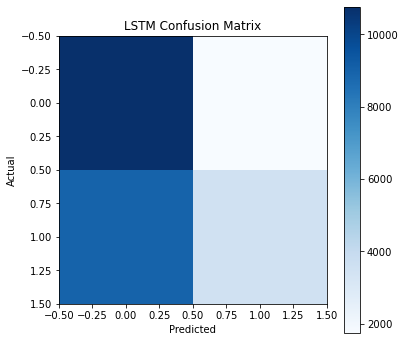

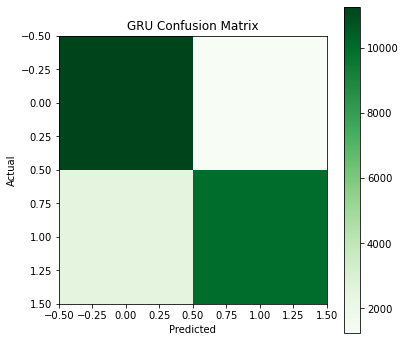


========== LSTM ==========
              precision    recall  f1-score   support

    Negative       0.54      0.86      0.67     12500
    Positive       0.67      0.28      0.40     12500

    accuracy                           0.57     25000
   macro avg       0.61      0.57      0.53     25000
weighted avg       0.61      0.57      0.53     25000


========== GRU ==========
              precision    recall  f1-score   support

    Negative       0.82      0.90      0.86     12500
    Positive       0.89      0.80      0.84     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



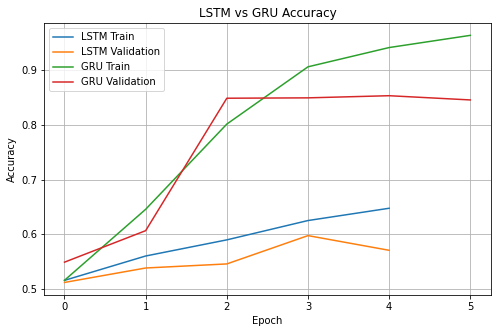

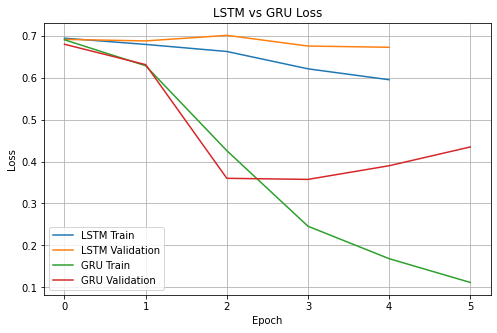


EXPERIMENT 9 COMPLETED SUCCESSFULLY!


In [1]:

# EXPERIMENT 9: IMDB SENTIMENT ANALYSIS USING LSTM AND GRU

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, GRU, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix, classification_report

# 1. LOAD IMDB DATASET
vocab_size = 10000
max_length = 200

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training Samples:", X_train.shape)
print("Testing Samples:", X_test.shape)
print("First Review:", X_train[0])
print("Sentiment Label:", y_train[0])

# 2. PAD SEQUENCES
X_train = pad_sequences(
    X_train, maxlen=max_length,
    padding="post", truncating="post"
)

X_test = pad_sequences(
    X_test, maxlen=max_length,
    padding="post", truncating="post"
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

# 3. DECODE FIRST REVIEW
word_index = imdb.get_word_index()

reverse_word_index = {
    value + 3: key for key, value in word_index.items()
}

reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"
reverse_word_index[3] = "<UNUSED>"

decoded_review = " ".join(
    reverse_word_index.get(i, "?") for i in X_train[0]
)

print("\nDecoded Review:\n", decoded_review)
print("Sentiment:", "Positive" if y_train[0] == 1 else "Negative")

# 4. BUILD LSTM MODEL
embedding_dim = 128

lstm_model = Sequential([
    Input(shape=(max_length,)),
    Embedding(vocab_size, embedding_dim),
    LSTM(128),
    Dropout(0.5),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid")
])

lstm_model.summary()

# 5. COMPILE LSTM
lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 6. TRAIN LSTM
history_lstm = lstm_model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=5,
    batch_size=64,
    verbose=1
)

# 7. EVALUATE LSTM
loss_lstm, accuracy_lstm = lstm_model.evaluate(
    X_test, y_test, verbose=0
)

print("\nLSTM Test Loss:", loss_lstm)
print("LSTM Test Accuracy:", accuracy_lstm)

# 8. BUILD GRU MODEL
gru_model = Sequential([
    Input(shape=(max_length,)),
    Embedding(vocab_size, embedding_dim),
    GRU(128),
    Dropout(0.5),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid")
])

gru_model.summary()

# 9. COMPILE GRU
gru_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 10. EARLY STOPPING
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# 11. TRAIN GRU
history_gru = gru_model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

# 12. EVALUATE GRU
loss_gru, accuracy_gru = gru_model.evaluate(
    X_test, y_test, verbose=0
)

print("\nGRU Test Loss:", loss_gru)
print("GRU Test Accuracy:", accuracy_gru)

# 13. COMPARE MODELS
comparison = pd.DataFrame({
    "Model": ["LSTM", "GRU"],
    "Loss": [loss_lstm, loss_gru],
    "Accuracy": [accuracy_lstm, accuracy_gru]
})

print("\nMODEL COMPARISON")
print(comparison)

# 14. MAKE PREDICTIONS
y_pred_lstm = (lstm_model.predict(X_test) > 0.5).astype(int)
y_pred_gru = (gru_model.predict(X_test) > 0.5).astype(int)

print("\nLSTM Prediction Shape:", y_pred_lstm.shape)
print("GRU Prediction Shape:", y_pred_gru.shape)

# 15. LSTM CONFUSION MATRIX
cm_lstm = confusion_matrix(y_test, y_pred_lstm)

plt.figure(figsize=(6, 6))
plt.imshow(cm_lstm, cmap="Blues")
plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.show()

# 16. GRU CONFUSION MATRIX
cm_gru = confusion_matrix(y_test, y_pred_gru)

plt.figure(figsize=(6, 6))
plt.imshow(cm_gru, cmap="Greens")
plt.title("GRU Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.show()

# 17. CLASSIFICATION REPORT
print("\n========== LSTM ==========")
print(classification_report(
    y_test,
    y_pred_lstm,
    target_names=["Negative", "Positive"]
))

print("\n========== GRU ==========")
print(classification_report(
    y_test,
    y_pred_gru,
    target_names=["Negative", "Positive"]
))

# 18. ACCURACY COMPARISON GRAPH
plt.figure(figsize=(8, 5))

plt.plot(history_lstm.history["accuracy"], label="LSTM Train")
plt.plot(history_lstm.history["val_accuracy"], label="LSTM Validation")
plt.plot(history_gru.history["accuracy"], label="GRU Train")
plt.plot(history_gru.history["val_accuracy"], label="GRU Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM vs GRU Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# 19. LOSS COMPARISON GRAPH
plt.figure(figsize=(8, 5))

plt.plot(history_lstm.history["loss"], label="LSTM Train")
plt.plot(history_lstm.history["val_loss"], label="LSTM Validation")
plt.plot(history_gru.history["loss"], label="GRU Train")
plt.plot(history_gru.history["val_loss"], label="GRU Validation")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM vs GRU Loss")
plt.legend()
plt.grid(True)
plt.show()

print("\nEXPERIMENT 9 COMPLETED SUCCESSFULLY!")
